# Predicting House Prices in Ames, Iowa

**Team:** Jasper Nash, Jaden Kwon, Akhil Lewis
**Competition:** [Regression for house prices](https://www.kaggle.com/competitions/regression-for-house-prices) (scored on RMSE in dollars)

We predict `SalePrice` for 260 test houses. We start with a very simple model and add one idea at a time:

1. Baselines: predict the average price, then a linear regression on overall quality
2. More features, prepared with a scikit-learn `Pipeline`
3. Polynomial features, and how to spot overfitting
4. Predicting log(price)

**Final model:** `LinearRegression` on log(price) with 16 features, **about \$21,000 RMSE** on held-out houses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PolynomialFeatures, StandardScaler

## 1. Load the data

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, " test:", test.shape)
train[["OverallQual", "GrLivArea", "Neighborhood", "KitchenQual", "SalePrice"]].head()

train: (1200, 81)  test: (260, 80)


,OverallQual,GrLivArea,Neighborhood,KitchenQual,SalePrice
0,7,1710,CollgCr,Gd,208500
1,6,1262,Veenker,TA,181500
2,7,1786,CollgCr,Gd,223500
3,7,1717,Crawfor,Gd,140000
4,8,2198,NoRidge,Gd,250000


## 2. Explore

Which numeric columns move most with price? Overall quality and living area are the strongest.

The scatter plot shows one house that breaks the pattern: a huge (4,676 sq ft) top-quality house that sold for
only \$184,750 because it was sold before it was finished. We drop houses over 4,500 sq ft from training so this
one sale doesn't pull the model's trend line down.

OverallQual     0.79
GrLivArea       0.74
TotalBsmtSF     0.64
GarageCars      0.64
GarageArea      0.62
1stFlrSF        0.62
FullBath        0.57
TotRmsAbvGrd    0.56
Name: SalePrice, dtype: float64


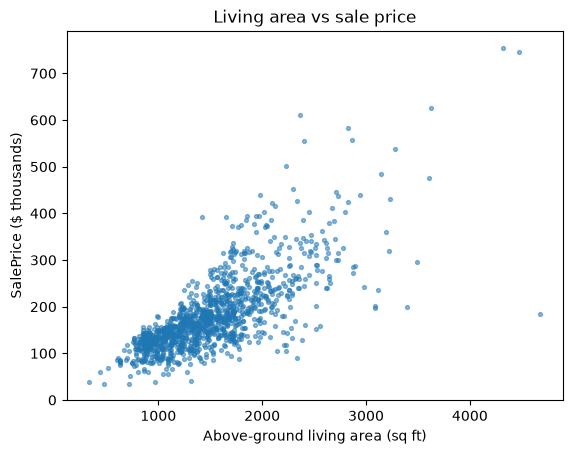

1199 training houses


In [3]:
print(train.select_dtypes("number").corr()["SalePrice"].drop(["SalePrice", "Id"]).nlargest(8).round(2))

plt.scatter(train.GrLivArea, train.SalePrice / 1000, s=8, alpha=0.5)
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("SalePrice ($ thousands)")
plt.title("Living area vs sale price")
plt.show()

train = train[train.GrLivArea < 4500]
print(len(train), "training houses")

## 3. Choose features

We use 16 columns in three groups, each prepared differently:
- **Numeric** (11 columns): missing values are filled with the column mean using `SimpleImputer`.
- **Quality ratings** (3 columns): ratings go Po < Fa < TA < Gd < Ex, so `OrdinalEncoder` turns them into numbers
  in that order. A missing basement rating means there is no basement, so it's filled with `"None"` (lowest).
- **Categories** (2 columns): `Neighborhood` and `SaleCondition` have no natural order, so `OneHotEncoder` gives
  each value its own 0/1 column.

In [4]:
NUMERIC = ["OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars", "YearBuilt", "YearRemodAdd",
           "FullBath", "Fireplaces", "LotArea", "BsmtFinSF1", "OverallCond"]
QUALITY = ["ExterQual", "KitchenQual", "BsmtQual"]
CATEGORY = ["Neighborhood", "SaleCondition"]
QUALITY_ORDER = ["None", "Po", "Fa", "TA", "Gd", "Ex"]

FEATURES = NUMERIC + QUALITY + CATEGORY
X, y = train[FEATURES], train.SalePrice

## 4. Train/test split

We hold out 25% of the training houses. Each model is fit on the other 75%. **Train RMSE** is the error on houses
the model has seen, and **test RMSE** is the error on houses it hasn't. Test RMSE is our estimate of the Kaggle
score. When train RMSE is much lower than test RMSE, the model is overfitting.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
results = {}


def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))


def evaluate(name, model, columns=FEATURES, log_price=False):
    """Fit on the training split and print train and test RMSE in dollars."""
    model.fit(X_train[columns], np.log(y_train) if log_price else y_train)
    train_pred, test_pred = model.predict(X_train[columns]), model.predict(X_test[columns])
    if log_price:
        train_pred, test_pred = np.exp(train_pred), np.exp(test_pred)
    results[name] = {"train RMSE": rmse(y_train, train_pred), "test RMSE": rmse(y_test, test_pred)}
    print(f"{name:25s} train ${results[name]['train RMSE']:>8,.0f}   test ${results[name]['test RMSE']:>8,.0f}")

## 5. Baselines

The simplest possible "model" predicts the average price for every house. Next, a linear regression on
`OverallQual` alone.

In [6]:
results["Predict the mean"] = {"train RMSE": rmse(y_train, np.full(len(y_train), y_train.mean())),
                              "test RMSE": rmse(y_test, np.full(len(y_test), y_train.mean()))}
print(f"{'Predict the mean':25s} test ${results['Predict the mean']['test RMSE']:>8,.0f}")
evaluate("OverallQual only", LinearRegression(), columns=["OverallQual"])

Predict the mean          test $  79,207
OverallQual only          train $  50,128   test $  47,945


## 6. All features in a pipeline

`make_column_transformer` applies the right preparation to each column group, and `make_pipeline` chains it
with the model. Because the preparation is part of the model, the exact same steps run on the Kaggle test set.

`build_model(degree)` can also add polynomial terms (squares and products) of the numeric columns, which we try
next. The `StandardScaler` puts the columns on the same scale before they are multiplied together.

In [7]:
def build_model(degree=1):
    numeric = make_pipeline(SimpleImputer(), StandardScaler(), PolynomialFeatures(degree, include_bias=False))
    quality = make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                            OrdinalEncoder(categories=[QUALITY_ORDER] * len(QUALITY)))
    preprocess = make_column_transformer(
        (numeric, NUMERIC),
        (quality, QUALITY),
        (OneHotEncoder(handle_unknown="ignore"), CATEGORY),
    )
    return make_pipeline(preprocess, LinearRegression())


evaluate("All 16 features", build_model())

All 16 features           train $  27,921   test $  26,421


## 7. Polynomial features and overfitting

Price doesn't rise in a straight line with quality and size: better houses gain value faster. Polynomial terms
let a linear model bend. We compare degrees 1 to 3:

Polynomial degree 2       train $  19,588   test $  22,527


Polynomial degree 3       train $  12,838   test $  38,914


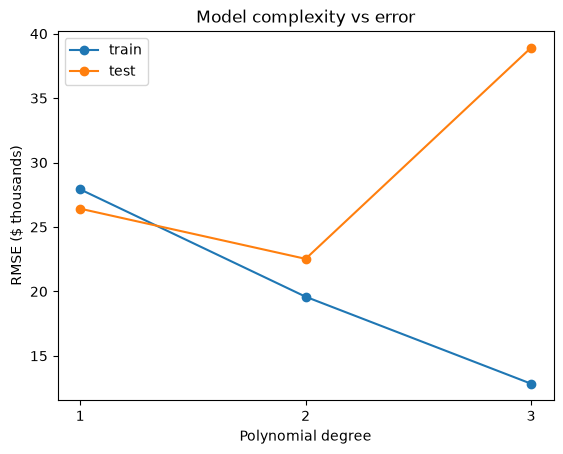

In [8]:
for d in [2, 3]:
    evaluate(f"Polynomial degree {d}", build_model(degree=d))

poly = pd.DataFrame(results).T.loc[["All 16 features", "Polynomial degree 2", "Polynomial degree 3"]]
plt.plot([1, 2, 3], poly["train RMSE"] / 1000, marker="o", label="train")
plt.plot([1, 2, 3], poly["test RMSE"] / 1000, marker="o", label="test")
plt.xticks([1, 2, 3])
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE ($ thousands)")
plt.title("Model complexity vs error")
plt.legend()
plt.show()

Train error keeps falling as the model gets more complex, because it can fit the houses it has seen more and
more closely. Test error improves at degree 2, then gets much worse at degree 3. **Degree 3 is overfitting**: it
fits noise in the training houses, so its predictions on new houses get worse.

## 8. Predicting log(price)

House price errors are roughly proportional: being off by \$20k is a big miss on a \$100k house but a small one
on a \$500k house. Training on `log(SalePrice)` and converting predictions back with `exp()` makes the model work
in percentages instead of dollars. It also straightens out much of the curve that the polynomial terms were
capturing, so a plain degree 1 model may be enough.

In [9]:
evaluate("log(price), degree 1", build_model(degree=1), log_price=True)
evaluate("log(price), degree 2", build_model(degree=2), log_price=True)

log(price), degree 1      train $  20,710   test $  20,783
log(price), degree 2      train $  18,881   test $  20,979


With log(price), degree 1 does as well as degree 2, and better than every model on raw prices. When two models
score about the same, we keep the simpler one.

**Final model: `LinearRegression` on log(price) with the 16 features, no polynomial terms.**

## 9. Summary of all models

In [10]:
summary = pd.DataFrame(results).T.sort_values("test RMSE", ascending=False)
summary.map("${:,.0f}".format)

,train RMSE,test RMSE
Predict the mean,"$81,734","$79,207"
OverallQual only,"$50,128","$47,945"
Polynomial degree 3,"$12,838","$38,914"
All 16 features,"$27,921","$26,421"
Polynomial degree 2,"$19,588","$22,527"
"log(price), degree 2","$18,881","$20,979"
"log(price), degree 1","$20,710","$20,783"


## 10. Final fit and submission

We fit the final model on **all** training houses, predict the 260 test houses, and write the submission. The
test houses are numbered by row (`Id` 0 to 259).

In [11]:
final_model = build_model(degree=1).fit(X, np.log(y))
predictions = np.exp(final_model.predict(test[FEATURES]))

submission = pd.DataFrame({"Id": test.index, "SalePrice": predictions})
submission.to_csv("submissions/submission.csv", index=False)
print(f"wrote {len(submission)} predictions")
submission.head()

wrote 260 predictions


,Id,SalePrice
0,0,94586.369569
1,1,192804.011720
2,2,136492.464573
3,3,209160.632270
4,4,139836.299478


## 11. Results and what we learned

| Submission | Kaggle score |
|---|---|
| First submission: 13-feature Ridge regression | \$25,571 |
| **Final: linear regression on log(price), 16 features** | _[add score]_ |

1. **Start simple and add one idea at a time.** Going from one feature to 16 cut the test error almost in half.
2. **More complexity isn't always better.** Degree 2 polynomials helped, degree 3 overfit. Comparing train and
   test error is what showed it.
3. **Transforming the target can replace complexity.** Predicting log(price) let a plain linear regression beat
   the polynomial models.

**With more time** we would try more features, regularized models (Ridge and Lasso), and cross-validation to
compare models more reliably than a single train/test split.